# Forecasting 14 Daerah Tertinggal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import math
from sklearn.linear_model import LinearRegression

In [2]:
dfx = pd.read_csv('/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/Clean-Water-Access/cluster_1.csv')
dfx

,daerah,1996,2009,2020,Cluster_KMeans,Cluster_HC,Konsistensi,id,provinsi,water,pad,morbid,expend,pop
0,Sambas,15.71,7.370,8.66,0,0,Solid 1,ID.KB.SM,Kalimantan Barat,8.66,1.296765e+11,31.05,1.692191e+12,538405.0
1,Pontianak,14.35,14.525,32.65,0,0,Solid 1,ID.KB.PR,Kalimantan Barat,20.79,9.861521e+10,26.88,9.462852e+11,267119.0
2,Nias,8.64,20.850,26.29,0,0,Solid 1,ID.SU.NI,Sumatera Utara,26.29,1.037554e+11,26.44,9.020785e+11,139428.0
3,Indragiri Hilir,0.29,8.210,30.44,0,0,Solid 1,ID.RI.II,Riau,30.44,1.809597e+11,26.04,1.963650e+12,749813.0
4,Rejang Lebong,24.00,30.370,34.32,0,0,Solid 1,ID.BE.RL,Bengkulu,34.32,6.919050e+10,29.93,1.033917e+12,261802.0
5,Bengkulu Selatan,12.99,22.820,37.39,0,0,Solid 1,ID.BE.BS,Bengkulu,37.39,8.614540e+10,34.51,1.029807e+12,159683.0
6,Lampung Barat,17.55,28.870,39.38,0,0,Solid 1,ID.LA.LB,Lampung,39.38,6.121947e+10,28.74,9.846380e+11,304874.0
7,Tana Toraja,25.75,29.970,40.14,0,0,Solid 1,ID.SE.TT,Sulawesi Selatan,40.14,1.109361e+11,20.44,1.112243e+12,235103.0
8,Lebak,26.53,24.410,41.55,0,0,Solid 1,ID.BT.LE,Banten,41.55,3.775044e+11,42.21,2.497003e+12,1308406.0
9,Ketapang,11.96,32.270,42.83,0,0,Solid 1,ID.KB.KE,Kalimantan Barat,42.83,2.312833e+11,15.31,2.144283e+12,521412.0


In [4]:
df = pd.read_csv('../data/clean_water.csv')

df_cluster = pd.read_csv('Hasil_KMeans_AksesAir.csv')
# solid1_daerah = df_cluster[df_cluster['Cluster_KMeans'] == 0]['daerah'].tolist()

solid1_daerah = dfx['daerah'].tolist()
solid1_daerah

['Sambas',
 'Pontianak',
 'Nias',
 'Indragiri Hilir',
 'Rejang Lebong',
 'Bengkulu Selatan',
 'Lampung Barat',
 'Tana Toraja',
 'Lebak',
 'Ketapang',
 'Lahat',
 'Pontianak',
 'Tapanuli Selatan',
 'Bengkulu Utara',
 'Sanggau',
 'Pandeglang',
 'Timor Tengah Selatan',
 'Garut',
 'Lampung Tengah',
 'Musi Rawas',
 'Kapuas',
 'Tanah Laut',
 'Merangin',
 'Barito Kuala',
 'Cianjur',
 'Batang Hari',
 'Sumba Barat',
 'Tapanuli Tengah']

In [5]:


# # Ambil 14 daerah terbawah dari Solid 1 berdasarkan akses air (water) tahun 2020
# df_2020 = df[(df['year'] == 2020) & (df['daerah'].isin(solid1_daerah))]
# bottom14 = df_2020.nsmallest(14, 'water')['daerah'].tolist()
# print("14 Daerah Tertinggal (Solid 1):", bottom14)

# # Load Model XGBoost yang sudah dilatih
with open('Model_AirBersih_.pkl', 'rb') as file:
    model_forecast = pickle.load(file)
    
# FIX: OneHotEncoder drop='first' on 'year' causes error for future years.
# We will temporarily change handle_unknown to 'ignore' to prevent error on unknown years like 2025
model_forecast.named_steps['preprocessing'].transformers_[0][1].handle_unknown = 'ignore'


In [6]:
def project_feature(df_daerah, feature, years_future):
    X = df_daerah['year'].values.reshape(-1, 1)
    y = df_daerah[feature].values
    reg = LinearRegression().fit(X, y)
    return reg.predict(np.array(years_future).reshape(-1, 1))

forecast_years = [2025, 2030, 2035, 2040, 2045]
all_forecasts = []

for daerah in solid1_daerah:
    df_d = df[df['daerah'] == daerah].sort_values('year')
    last_row = df_d[df_d['year'] == 2020].iloc[0]

    for yr in forecast_years:
        row = {
            'year': yr,
            'daerah': daerah,
            'tingkat': last_row['tingkat'],
            'status': last_row['status'],
            'logpop': project_feature(df_d, 'logpop', [yr])[0],
            'logarea': float(last_row['logarea']),
            'logpad': project_feature(df_d, 'logpad', [yr])[0],
            'morbid': project_feature(df_d, 'morbid', [yr])[0],
        }
        all_forecasts.append(row)

df_forecast = pd.DataFrame(all_forecasts)

# Lakukan prediksi menggunakan model .pkl
features_order = ['logpop', 'logarea', 'logpad', 'year', 'morbid', 'daerah', 'tingkat', 'status']
df_forecast['water'] = model_forecast.predict(df_forecast[features_order])
# Batasi nilai persentase di rentang [0, 100]
df_forecast['water'] = df_forecast['water'].clip(0, 100)

print(df_forecast[['daerah', 'year', 'water']].head(8))

      daerah  year      water
0     Sambas  2025  47.388344
1     Sambas  2030  53.428989
2     Sambas  2035  53.318027
3     Sambas  2040  55.935314
4     Sambas  2045  55.171688
5  Pontianak  2025  40.105927
6  Pontianak  2030  39.453262
7  Pontianak  2035  38.452164


/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


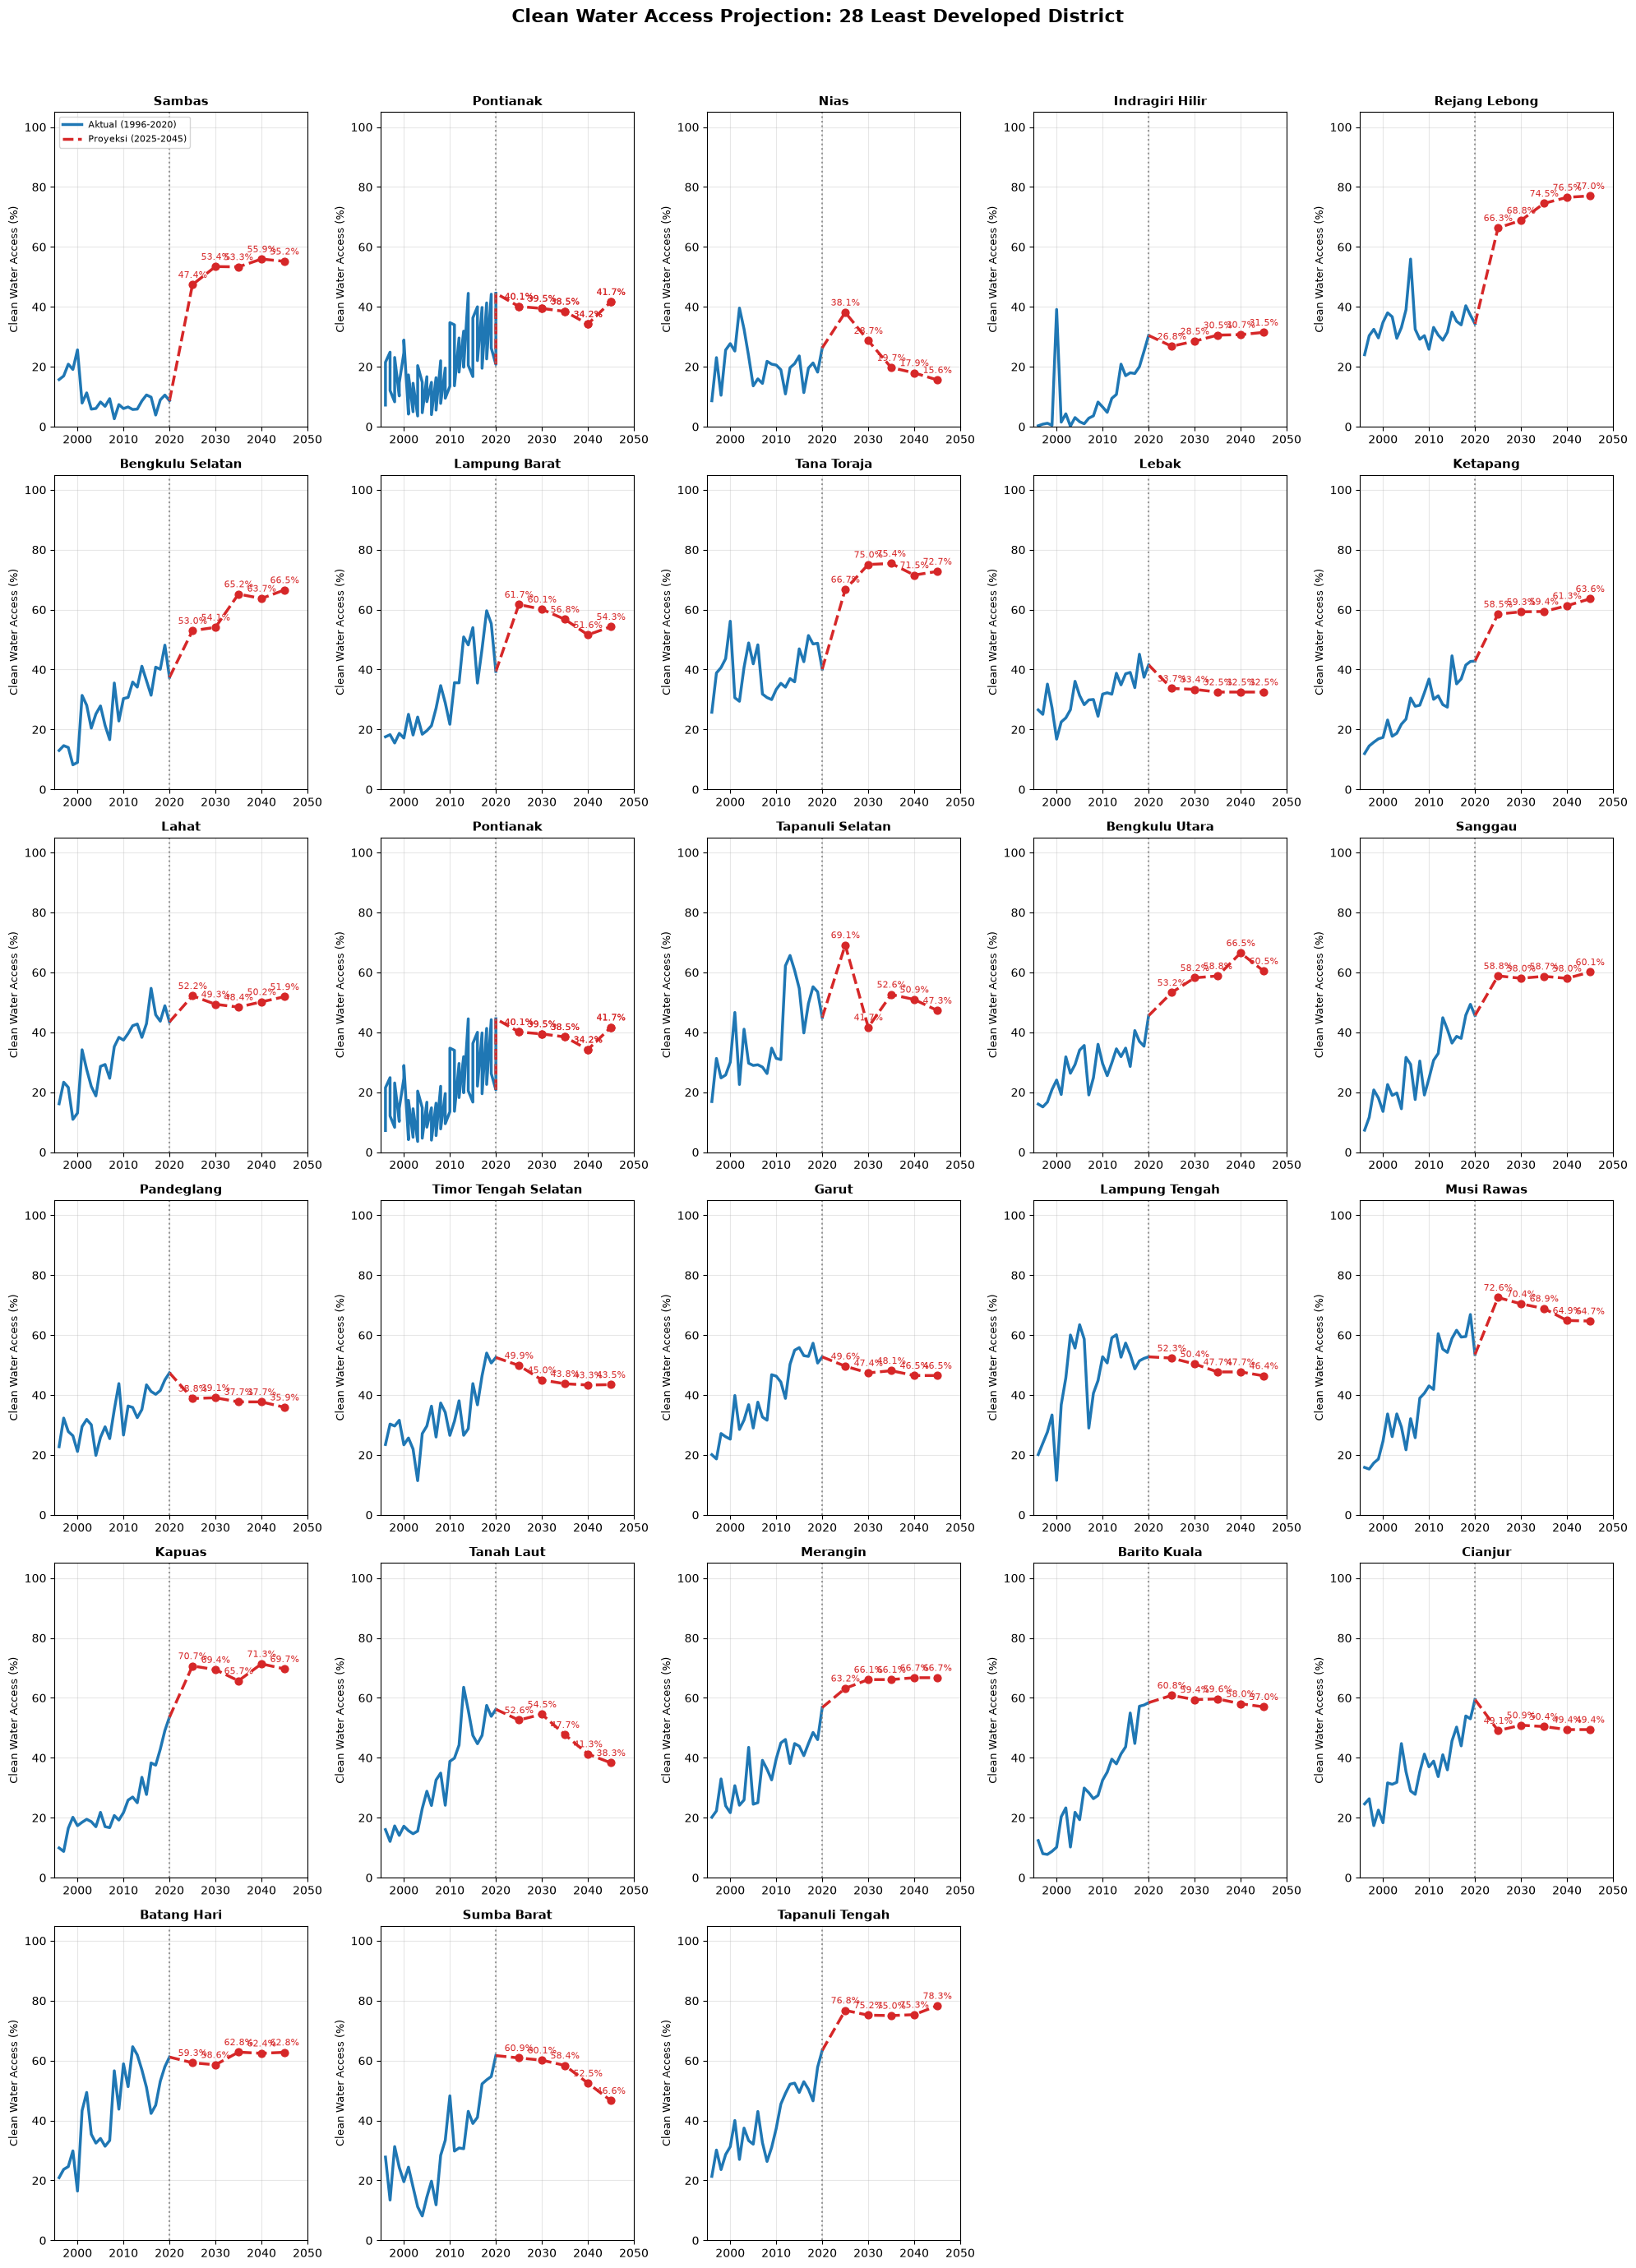

In [12]:
ncols = 5
nrows = math.ceil(len(solid1_daerah) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, nrows * 4.5))
axes = axes.flatten()

for i, daerah in enumerate(solid1_daerah):
    ax = axes[i]
    
    # Ambil data aktual (1996 - 2020)
    actual_data = df[df['daerah'] == daerah].sort_values('year')[['year', 'water']]
    
    # Ambil data forecast (2025, 2030, 2040, 2045)
    forecast_data = df_forecast[df_forecast['daerah'] == daerah].sort_values('year')[['year', 'water']]
    
    # Ambil titik tahun 2020 sebagai penyambung garis
    last_actual = actual_data[actual_data['year'] == 2020]
    
    # Gabungkan titik 2020 dengan data forecast agar garis bersambung
    connected_forecast = pd.concat([last_actual, forecast_data]).reset_index(drop=True)
    
    # Plot Actual (Solid Line)
    ax.plot(actual_data['year'], actual_data['water'], color='#1f77b4', lw=2.5, label='Aktual (1996-2020)')
    
    # Plot Forecast (Dashed Line)
    ax.plot(connected_forecast['year'], connected_forecast['water'], color='#d62728', lw=2.5, ls='--', label='Proyeksi (2025-2045)')
    
    # Tambahkan marker bulat di titik-titik forecast
    ax.scatter(forecast_data['year'], forecast_data['water'], color='#d62728', s=40, zorder=5)
    
    # Beri label persentase pada titik forecast
    for _, row in forecast_data.iterrows():
        ax.annotate(f"{row['water']:.1f}%",
                    xy=(row['year'], row['water']),
                    xytext=(0, 6), textcoords='offset points',
                    ha='center', fontsize=8, color='#d62728')
    
    # Garis pembatas tahun 2020
    ax.axvline(2020, color='gray', ls=':', alpha=0.8)
    
    ax.set_title(daerah, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 105)
    ax.set_xlim(1995, 2050)
    ax.set_ylabel('Clean Water Access (%)', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    if i == 0:
        ax.legend(fontsize=8, loc='upper left')

# Sembunyikan axes yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Clean Water Access Projection: 28 Least Developed District', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

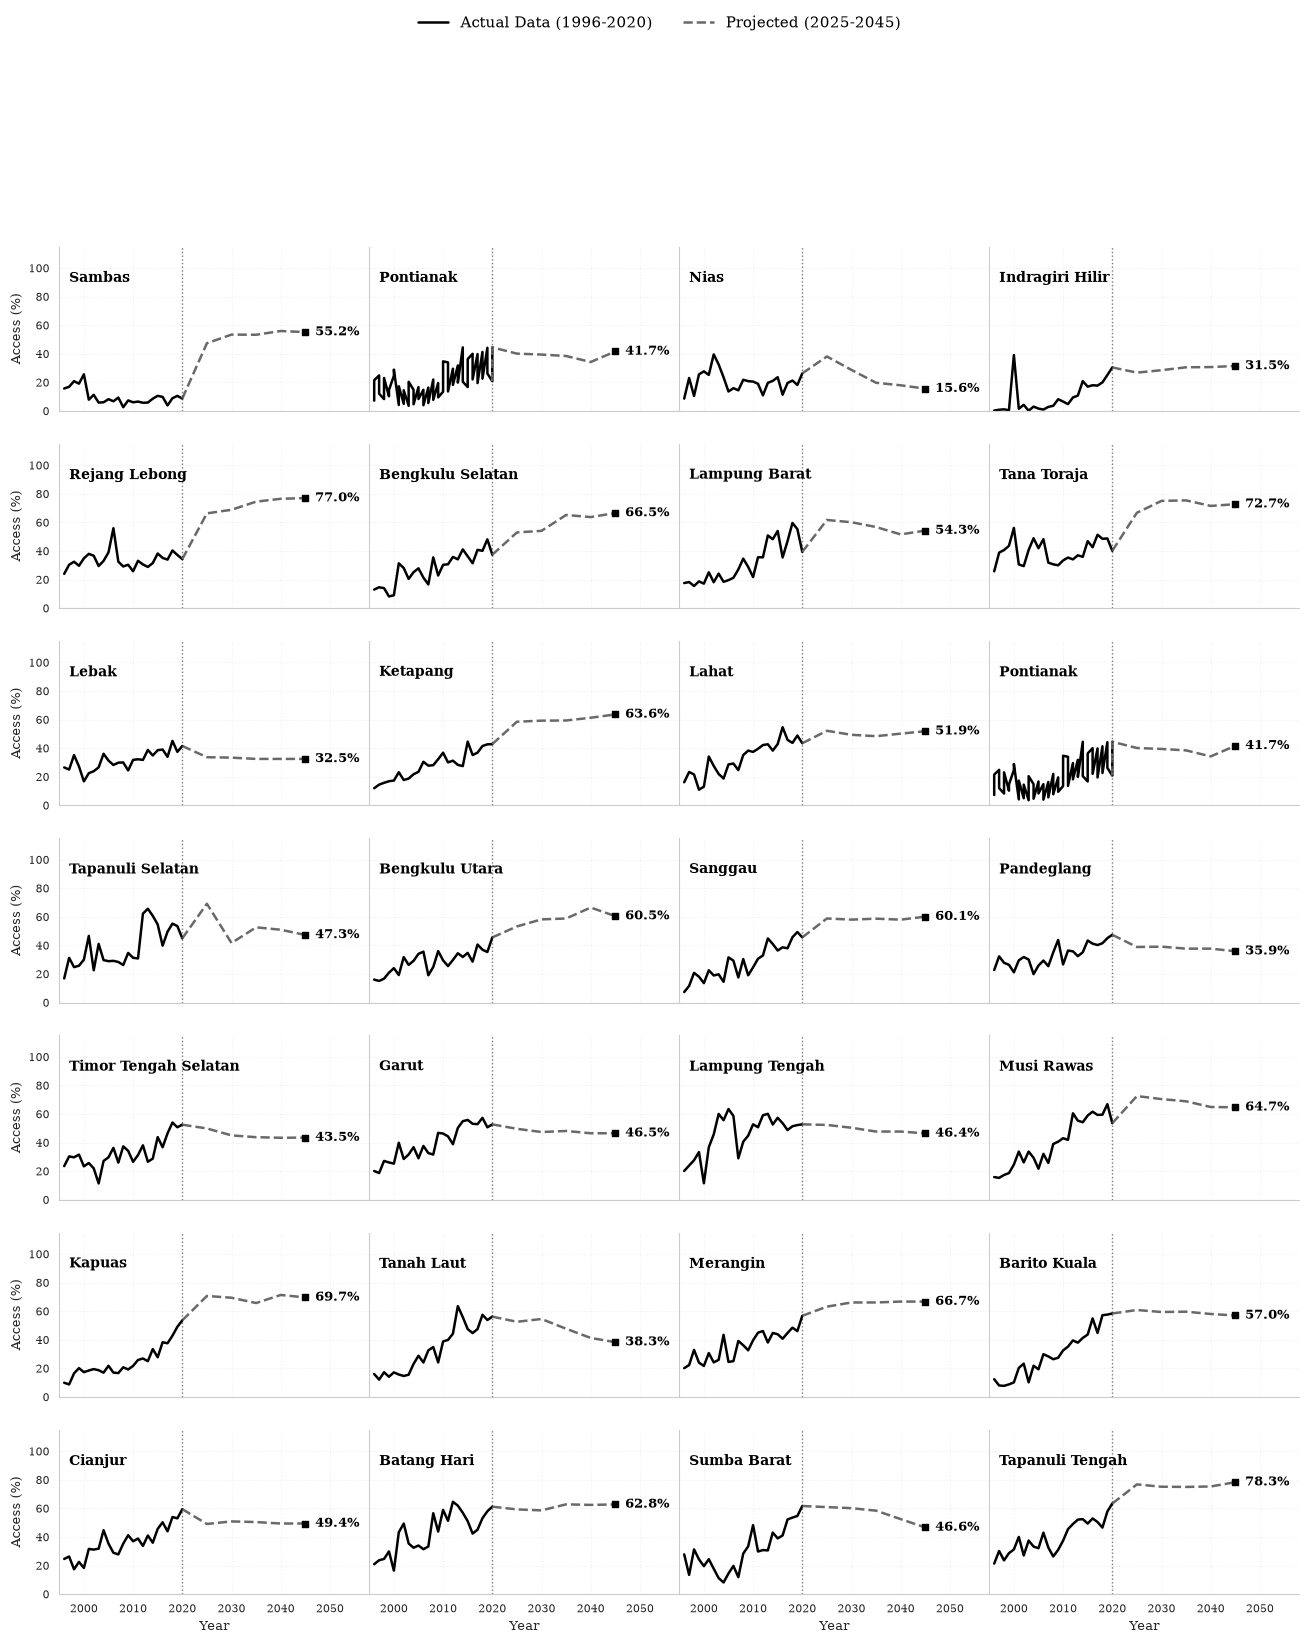

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

# 1. Konfigurasi Standar Jurnal (Hitam-Putih, Font Serif, Minimalis)
plt.rcParams['font.family'] = 'serif' 
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = ':'
plt.rcParams['text.color'] = 'black'

ncols = 4
nrows = math.ceil(len(solid1_daerah) / ncols)

# ShareX & ShareY merapatkan plot, menghemat ruang secara signifikan
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, nrows * 2.5), sharex=True, sharey=True)
axes = axes.flatten()

for i, daerah in enumerate(solid1_daerah):
    ax = axes[i]
    
    actual_data = df[df['daerah'] == daerah].sort_values('year')[['year', 'water']]
    forecast_data = df_forecast[df_forecast['daerah'] == daerah].sort_values('year')[['year', 'water']]
    
    last_actual = actual_data[actual_data['year'] == 2020]
    connected_forecast = pd.concat([last_actual, forecast_data]).reset_index(drop=True)
    
    # 2. GRAYSCALE FRIENDLY
    # Data Aktual: Hitam, Solid, Tebal
    ax.plot(actual_data['year'], actual_data['water'], color='black', lw=1.8, label='Actual Data (1996-2020)' if i==0 else "")
    
    # Data Proyeksi: Abu-abu Gelap (DimGray), Dashed
    ax.plot(connected_forecast['year'], connected_forecast['water'], color='dimgray', lw=1.8, ls='--', label='Projected (2025-2045)' if i==0 else "")
    
    # 3. Anotasi Tunggal yang Rapi (Hanya di 2045)
    last_val = connected_forecast.iloc[-1]['water']
    ax.scatter(2045, last_val, color='black', marker='s', s=15, zorder=5) # Marker kotak (square) hitam
    ax.text(2047, last_val, f"{last_val:.1f}%", fontsize=9, va='center', ha='left', fontweight='bold', color='black')
    
    # Pembatas Tahun 2020
    ax.axvline(2020, color='black', ls=':', lw=1, alpha=0.5)
    
    # 4. Efisiensi Spasi Vertikal: Nama Daerah ditaruh di DALAM grafik (Kiri Atas)
    ax.text(1997, 98, daerah, fontsize=10, fontweight='bold', va='top', ha='left')
    
    ax.set_ylim(0, 115)
    ax.set_xlim(1995, 2058) # Ruang ekstra di kanan untuk teks anotasi 2045
    
    # Label sumbu HANYA pada sisi terluar grid
    if i % ncols == 0:
        ax.set_ylabel('Access (%)', fontsize=9)
    if i >= len(solid1_daerah) - ncols:
        ax.set_xlabel('Year', fontsize=9)
        
    ax.tick_params(axis='both', which='major', labelsize=8)

# Hapus frame yang kosong jika jumlah data ganjil
for j in range(len(solid1_daerah), len(axes)):
    fig.delaxes(axes[j])

# 5. Global Legend: Satu legenda saja di atas secara horizontal
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=11)

plt.subplots_adjust(wspace=0)


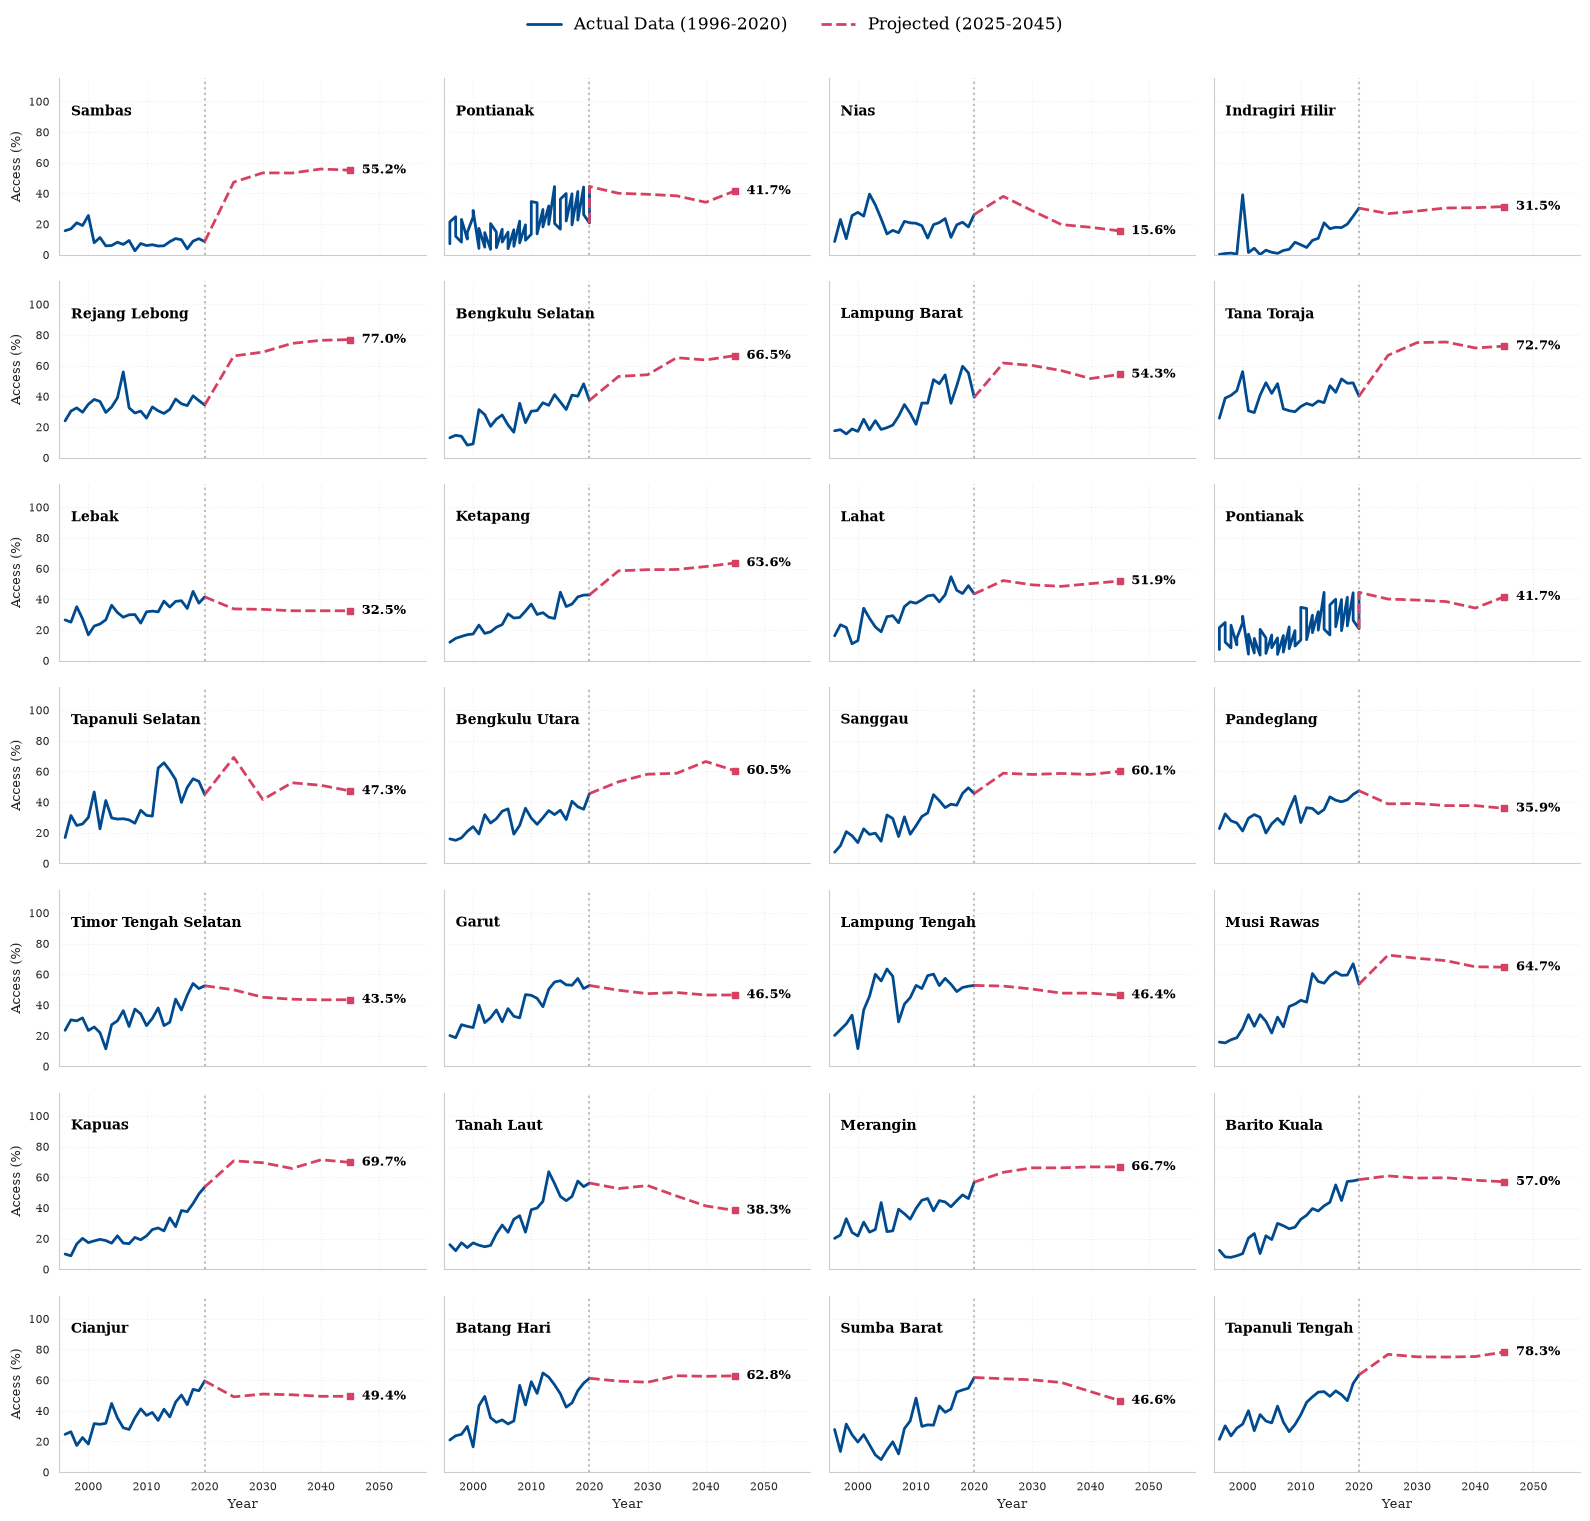

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

# 1. Konfigurasi Standar Jurnal (Font Serif)
plt.rcParams['font.family'] = 'serif' 
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = ':'
plt.rcParams['text.color'] = 'black'

ncols = 4
nrows = math.ceil(len(solid1_daerah) / ncols)

# ShareX & ShareY
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, nrows * 2.2), sharex=True, sharey=True)
axes = axes.flatten()

# 2. Palet Warna "Grayscale-Safe"
color_actual = '#004A8F'   # Deep Blue (Saat diprint B/W akan jadi Abu-abu sangat gelap / mendekati Hitam)
color_forecast = '#D64161' # Deep Red-Pink (Saat diprint B/W akan jadi Abu-abu terang, kontrasnya jelas)

for i, daerah in enumerate(solid1_daerah):
    ax = axes[i]
    
    actual_data = df[df['daerah'] == daerah].sort_values('year')[['year', 'water']]
    forecast_data = df_forecast[df_forecast['daerah'] == daerah].sort_values('year')[['year', 'water']]
    
    last_actual = actual_data[actual_data['year'] == 2020]
    connected_forecast = pd.concat([last_actual, forecast_data]).reset_index(drop=True)
    
    # Data Aktual (Solid line)
    ax.plot(actual_data['year'], actual_data['water'], color=color_actual, lw=2, label='Actual Data (1996-2020)' if i==0 else "")
    
    # Data Proyeksi (Dashed line)
    ax.plot(connected_forecast['year'], connected_forecast['water'], color=color_forecast, lw=2, ls='--', label='Projected (2025-2045)' if i==0 else "")
    
    # Anotasi Akhir
    last_val = connected_forecast.iloc[-1]['water']
    ax.scatter(2045, last_val, color=color_forecast, marker='s', s=20, zorder=5) # Kotak
    ax.text(2047, last_val, f"{last_val:.1f}%", fontsize=9, va='center', ha='left', fontweight='bold', color='black')
    
    # Pembatas 2020
    ax.axvline(2020, color='gray', ls=':', lw=1.5, alpha=0.5)
    
    # Nama Daerah di Kiri Atas Dalam Grafik
    ax.text(1997, 98, daerah, fontsize=10, fontweight='bold', va='top', ha='left')
    
    ax.set_ylim(0, 115)
    ax.set_xlim(1995, 2058) 
    
    # Sumbu Terluar
    if i % ncols == 0:
        ax.set_ylabel('Access (%)', fontsize=9)
    if i >= len(solid1_daerah) - ncols:
        ax.set_xlabel('Year', fontsize=9)
        
    ax.tick_params(axis='both', which='major', labelsize=8)

# Hapus subplot kosong
for j in range(len(solid1_daerah), len(axes)):
    fig.delaxes(axes[j])

# 3. FIX BUG SPACE KOSONG
# Eksekusi tight_layout dulu untuk merapikan seluruh elemen
plt.tight_layout()

# Lalu, modifikasi manual: sisakan 6% ruang di bagian atas (top=0.94), serta rapatkan spasi antar grid
plt.subplots_adjust(wspace=0.05, hspace=0.15, top=0.94)

# Tempatkan legend di koordinat Y=0.99 (tepat di atas plot, di dalam area 6% yang sudah dikosongkan)
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=2, frameon=False, fontsize=12)

plt.show()


# Posisi XGBOOST

Berdasarkan kode yang Anda berikan, berikut adalah penjelasan mengenai posisi XGBoost Anda dan bagaimana menjawab kritik tersebut, terutama jika target Anda adalah jurnal Q1.

### 1. Posisi XGBoost dalam Pipeline Anda
Di dalam kode ini, model forecasting Anda sebenarnya menggunakan pendekatan **Two-Stage Model (Model Dua Tahap)**:
*   **Tahap 1 (Skenario Sosioekonomi):** Anda menggunakan algoritma **Linear Regression (Regresi Linier Sederhana)** melalui fungsi `project_feature` untuk memproyeksikan variabel independen (populasi, pengeluaran, morbiditas) di masa depan (2025-2045) murni berdasarkan tren waktu (`year`).
*   **Tahap 2 (Prediksi Akses Air):** Anda menggunakan **XGBoost** (`model_forecast`) untuk memprediksi target utama (`water` access) menggunakan nilai variabel sosioekonomi yang *sudah diproyeksikan* di Tahap 1.

Jadi, posisi XGBoost di sini **bukan** memprediksi masa depan secara mandiri, melainkan **menerjemahkan skenario sosioekonomi masa depan menjadi tingkat akses air bersih**. XGBoost hanya membawa "pengetahuan" tentang bagaimana variabel $X$ memengaruhi $Y$ dari data historis, lalu menerapkannya pada $X$ masa depan.

### 2. Meluruskan Kritik ("Kalau populasi 2035 = populasi 2020...")
Kritik yang Anda sebutkan di atas sebenarnya **kurang tepat jika melihat kode Anda**. 

Di dalam kode, Anda **tidak** menggunakan populasi 2020 untuk memprediksi 2035. Anda memanggil fungsi ini:
`'logpop': project_feature(df_d, 'logpop', [yr])[0]`
Artinya, populasi (`logpop`), pendapatan/pengeluaran (`logpad`), dan morbiditas (`morbid`) untuk tahun 2035 didapatkan dari **ekstrapolasi garis lurus (linear regression)** dari data historis Anda. 

Yang Anda tetapkan statis (*fixed*) seperti tahun 2020 hanyalah luas wilayah (`logarea`), klasifikasi (`tingkat`), dan `status`. Hal ini wajar karena luas wilayah atau status administratif jarang berubah secara drastis.

### 3. Letak Masalah Sesungguhnya untuk Jurnal Q1
Meskipun Anda memproyeksikan variabelnya, metode ini tetap memiliki titik lemah yang akan diserang oleh reviewer jurnal Q1:

**Masalahnya adalah Asumsi Ekstraplorasi Linier yang Terlalu Naif.**
Menggunakan *univariate linear regression* (waktu vs variabel) untuk memprediksi populasi dan ekonomi sejauh 25 tahun ke depan (hingga 2045) dianggap terlalu menyederhanakan masalah. 
*   Populasi tidak tumbuh selamanya secara linier (biasanya logistik/melambat).
*   Ekonomi dipengaruhi oleh banyak guncangan, bukan sekadar garis lurus terhadap waktu.

### Bagaimana Memposisikan / Menulis Ini di Paper Q1?
Untuk menyelamatkan narasi paper Anda tanpa harus merombak kode besar-besaran, Anda harus jujur dan spesifik di metodologi. Jangan bilang "Kami menggunakan XGBoost untuk mem-forecast masa depan", tetapi gunakan bahasa seperti ini:

1.  **Sebut ini sebagai "Two-Stage Forecasting Framework":**
    *"We developed a two-stage forecasting framework. In the first stage, future socioeconomic drivers (population, expenditure, morbidity) up to 2045 were projected under a **historical linear trend scenario (Business-as-Usual / BAU)** using Ordinary Least Squares (OLS) extrapolation. In the second stage, an XGBoost model, trained on historical non-linear relationships, was applied to these projected covariates to forecast clean water access."*

2.  **Akui sebagai Skenario "Business-as-Usual" (BAU):**
    Jelaskan bahwa proyeksi Tahap 1 Anda adalah skenario BAU (apa yang terjadi jika tren masa lalu berlanjut lurus ke depan tanpa intervensi). Ini sah dalam sains sebagai *baseline scenario*.

**Saran Tambahan Jika Ingin Paper Lebih Kuat (Opsional):**
Reviewer Q1 sangat menyukai skenario yang terstandarisasi. Daripada memproyeksikan populasi atau ekonomi menggunakan `project_feature` (Linear Regression buatan sendiri), akan jauh lebih kuat jika nilai `logpop` dan `logpad` tahun 2035-2045 Anda masukkan dari **data proyeksi resmi** (misalnya Proyeksi Penduduk BPS, Bappenas, atau skenario SSP/Shared Socioeconomic Pathways dari IPCC).